# Métriques d'évaluation en NLP
## Summarization · Question Answering · Text Generation

Ce notebook applique les principales métriques d'évaluation sur des exemples courts et reproductibles.
Chaque section peut être copiée telle quelle dans la présentation.

**Plan**
1. Installation et imports
2. Summarization : ROUGE, BERTScore, taux de compression
3. Question Answering : Exact Match, F1 (SQuAD)
4. Text Generation : BLEU, chrF, METEOR, BERTScore, perplexité, diversité (distinct-n)
5. Tableau récapitulatif

## 1. Installation et imports

In [1]:
# À exécuter une seule fois (Colab / Jupyter)
!pip install -q evaluate rouge_score sacrebleu nltk bert_score transformers torch pandas matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import re, string, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import evaluate
import nltk
nltk.download("punkt", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
print("Imports OK")

Imports OK


## 2. Summarization

Objectif : mesurer la qualité d'un résumé généré par rapport à un résumé de référence.

| Métrique | Idée | Limite |
|---|---|---|
| ROUGE-1 / ROUGE-2 | Recouvrement d'unigrammes / bigrammes | Ignore le sens, sensible à la reformulation |
| ROUGE-L | Plus longue sous-séquence commune | Idem |
| BERTScore | Similarité sémantique via embeddings contextuels | Dépend du modèle utilisé |
| Taux de compression | Longueur du résumé / longueur du texte source | Ne mesure pas la qualité |

In [3]:
source = (
    "The city council approved a new budget on Tuesday that increases funding for public transport "
    "by 15 percent. The plan also includes money for new bike lanes and a pilot program offering "
    "free bus rides to students. Opponents argued that the tax increase needed to finance the plan "
    "would hurt small businesses."
)
reference = (
    "The city council approved a budget raising public transport funding by 15 percent, "
    "with bike lanes and free student bus rides."
)
candidate_good = (
    "The council approved a budget increasing public transport funding by 15 percent, "
    "adding bike lanes and free bus rides for students."
)
candidate_bad = (
    "Small businesses were hurt by new taxes announced by the mayor on Monday."
)

In [4]:
rouge = evaluate.load("rouge")

def rouge_scores(pred, ref):
    r = rouge.compute(predictions=[pred], references=[ref])
    return {k: round(v, 3) for k, v in r.items() if k in ("rouge1", "rouge2", "rougeL")}

print("Bon résumé    :", rouge_scores(candidate_good, reference))
print("Mauvais résumé:", rouge_scores(candidate_bad, reference))

Bon résumé    : {'rouge1': np.float64(0.81), 'rouge2': np.float64(0.6), 'rougeL': np.float64(0.81)}
Mauvais résumé: {'rouge1': np.float64(0.118), 'rouge2': np.float64(0.0), 'rougeL': np.float64(0.059)}


### ROUGE-N « à la main » (pour expliquer la formule)

In [5]:
def tokenize(text):
    return re.findall(r"\w+", text.lower())

def ngrams(tokens, n):
    return collections.Counter(tuple(tokens[i:i+n]) for i in range(len(tokens) - n + 1))

def rouge_n(pred, ref, n=1):
    p, r = ngrams(tokenize(pred), n), ngrams(tokenize(ref), n)
    overlap = sum((p & r).values())
    precision = overlap / max(sum(p.values()), 1)
    recall = overlap / max(sum(r.values()), 1)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"precision": round(precision, 3), "recall": round(recall, 3), "f1": round(f1, 3)}

print("ROUGE-1 :", rouge_n(candidate_good, reference, 1))
print("ROUGE-2 :", rouge_n(candidate_good, reference, 2))

ROUGE-1 : {'precision': 0.81, 'recall': 0.81, 'f1': 0.81}
ROUGE-2 : {'precision': 0.6, 'recall': 0.6, 'f1': 0.6}


In [6]:
bertscore = evaluate.load("bertscore")

def bert_scores(preds, refs, lang="en"):
    r = bertscore.compute(predictions=preds, references=refs, lang=lang)
    return {k: round(float(np.mean(r[k])), 3) for k in ("precision", "recall", "f1")}

print("Bon résumé    :", bert_scores([candidate_good], [reference]))
print("Mauvais résumé:", bert_scores([candidate_bad], [reference]))

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Bon résumé    : {'precision': 0.983, 'recall': 0.984, 'f1': 0.983}
Mauvais résumé: {'precision': 0.903, 'recall': 0.87, 'f1': 0.886}


In [7]:
def compression_ratio(summary, source):
    return round(len(summary.split()) / len(source.split()), 3)

print("Taux de compression (bon résumé):", compression_ratio(candidate_good, source))

Taux de compression (bon résumé): 0.404


### (Optionnel) Cohérence factuelle avec un modèle NLI
Un résumé peut avoir un bon ROUGE tout en inventant des faits (hallucination).
On teste si le texte source *implique* le résumé.

In [8]:
from transformers import pipeline
nli = pipeline("text-classification", model="facebook/bart-large-mnli")

def faithfulness(source, summary):
    out = nli({"text": source, "text_pair": summary}, top_k=None)
    return {o["label"]: round(o["score"], 3) for o in out}

print("Bon résumé    :", faithfulness(source, candidate_good))
print("Mauvais résumé:", faithfulness(source, candidate_bad))

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Bon résumé    : {'entailment': 0.993, 'neutral': 0.007, 'contradiction': 0.0}
Mauvais résumé: {'neutral': 0.555, 'contradiction': 0.442, 'entailment': 0.003}


## 3. Question Answering

Pour le QA extractif (type SQuAD), on compare la réponse prédite à une ou plusieurs réponses acceptées.

| Métrique | Définition |
|---|---|
| Exact Match (EM) | 1 si la réponse normalisée est identique à une référence, sinon 0 |
| F1 (au niveau des tokens) | Moyenne harmonique de la précision et du rappel des mots partagés |

Normalisation SQuAD : minuscules, suppression de la ponctuation, des articles (a, an, the) et des espaces multiples.

In [9]:
def normalize_answer(s):
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def exact_match(pred, golds):
    return float(any(normalize_answer(pred) == normalize_answer(g) for g in golds))

def f1_single(pred, gold):
    p, g = normalize_answer(pred).split(), normalize_answer(gold).split()
    common = collections.Counter(p) & collections.Counter(g)
    n_same = sum(common.values())
    if n_same == 0:
        return 0.0
    precision, recall = n_same / len(p), n_same / len(g)
    return 2 * precision * recall / (precision + recall)

def f1_score(pred, golds):
    return max(f1_single(pred, g) for g in golds)

In [10]:
qa_examples = [
    {"question": "Who wrote Les Misérables?",   "pred": "Victor Hugo",                 "golds": ["Victor Hugo"]},
    {"question": "Where is the Eiffel Tower?",  "pred": "in Paris, France",            "golds": ["Paris"]},
    {"question": "When did WWII end?",          "pred": "1945",                         "golds": ["1945", "in 1945"]},
    {"question": "Capital of Morocco?",         "pred": "Casablanca",                  "golds": ["Rabat"]},
    {"question": "What is the largest planet?", "pred": "The planet Jupiter",          "golds": ["Jupiter"]},
]
rows = []
for ex in qa_examples:
    rows.append({
        "question": ex["question"], "prédiction": ex["pred"], "références": ex["golds"],
        "EM": exact_match(ex["pred"], ex["golds"]),
        "F1": round(f1_score(ex["pred"], ex["golds"]), 3),
    })
df_qa = pd.DataFrame(rows)
display(df_qa)
print(f"EM global = {df_qa['EM'].mean():.2%} | F1 global = {df_qa['F1'].mean():.2%}")

,question,prédiction,références,EM,F1
0,Who wrote Les Misérables?,Victor Hugo,[Victor Hugo],1.0,1.000
1,Where is the Eiffel Tower?,"in Paris, France",[Paris],0.0,0.500
2,When did WWII end?,1945,"[1945, in 1945]",1.0,1.000
3,Capital of Morocco?,Casablanca,[Rabat],0.0,0.000
4,What is the largest planet?,The planet Jupiter,[Jupiter],0.0,0.667


EM global = 40.00% | F1 global = 63.34%


### Vérification avec la métrique officielle SQuAD (`evaluate`)

In [11]:
squad = evaluate.load("squad")
preds = [{"id": str(i), "prediction_text": ex["pred"]} for i, ex in enumerate(qa_examples)]
refs = [{"id": str(i), "answers": {"text": ex["golds"], "answer_start": [0] * len(ex["golds"])}}
        for i, ex in enumerate(qa_examples)]
print(squad.compute(predictions=preds, references=refs))

{'exact_match': 40.0, 'f1': 63.33333333333333}


**Remarque.** EM est très strict : « The planet Jupiter » obtient 0 alors que la réponse est correcte.
Le F1 donne un crédit partiel, d'où l'intérêt de rapporter les deux.

## 4. Text Generation

Pour la génération libre (traduction, dialogue, histoires), plusieurs réponses sont valides.
On combine des métriques de **recouvrement**, de **sémantique**, de **fluidité** et de **diversité**.

| Famille | Métriques |
|---|---|
| Recouvrement avec une référence | BLEU, chrF, METEOR |
| Similarité sémantique | BERTScore |
| Fluidité | Perplexité |
| Diversité | distinct-n, self-BLEU |
| Évaluation humaine / LLM-juge | Fluidité, cohérence, pertinence |

In [12]:
references = [["The cat is sitting on the mat near the window."]]
candidates = {
    "proche":      "The cat sits on the mat next to the window.",
    "reformulée":  "A feline is resting on the rug beside the window.",
    "hors sujet":  "The stock market closed higher on Friday.",
}

In [13]:
sacrebleu = evaluate.load("sacrebleu")
chrf = evaluate.load("chrf")
meteor = evaluate.load("meteor")

rows = []
for name, cand in candidates.items():
    rows.append({
        "candidat": name,
        "BLEU":   round(sacrebleu.compute(predictions=[cand], references=references)["score"], 2),
        "chrF":   round(chrf.compute(predictions=[cand], references=references)["score"], 2),
        "METEOR": round(meteor.compute(predictions=[cand], references=[references[0][0]])["meteor"], 3),
    })
df_gen = pd.DataFrame(rows).set_index("candidat")
display(df_gen)

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


,BLEU,chrF,METEOR
candidat,,,
proche,26.66,58.13,0.803
reformulée,18.36,44.42,0.511
hors sujet,5.00,14.68,0.187


In [14]:
# BERTScore : capture mieux la reformulation que BLEU
bs_rows = {}
for name, cand in candidates.items():
    bs_rows[name] = bert_scores([cand], [references[0][0]])["f1"]
df_gen["BERTScore F1"] = pd.Series(bs_rows)
display(df_gen)

,BLEU,chrF,METEOR,BERTScore F1
candidat,,,,
proche,26.66,58.13,0.803,0.984
reformulée,18.36,44.42,0.511,0.959
hors sujet,5.00,14.68,0.187,0.862


**À observer** : la phrase reformulée a un BLEU faible (peu de mots communs) mais un BERTScore élevé,
alors que la phrase hors sujet obtient des scores bas partout.

### Perplexité (fluidité) avec GPT-2

In [15]:
import torch
from transformers import GPT2LMHeadModel, GPT2TokenizerFast

tok = GPT2TokenizerFast.from_pretrained("gpt2")
lm = GPT2LMHeadModel.from_pretrained("gpt2").eval()

def perplexity(text):
    enc = tok(text, return_tensors="pt")
    with torch.no_grad():
        loss = lm(**enc, labels=enc["input_ids"]).loss
    return float(torch.exp(loss))

texts = {
    "fluide":     "The cat is sitting on the mat near the window.",
    "désordonné": "Window the near mat cat on sitting the is the.",
}
for k, t in texts.items():
    print(f"{k:12s} -> perplexité = {perplexity(t):.1f}")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


fluide       -> perplexité = 41.5
désordonné   -> perplexité = 3247.5


### Diversité : distinct-n et self-BLEU

In [16]:
def distinct_n(texts, n=2):
    all_ngrams = []
    for t in texts:
        toks = t.lower().split()
        all_ngrams += [tuple(toks[i:i+n]) for i in range(len(toks) - n + 1)]
    return len(set(all_ngrams)) / max(len(all_ngrams), 1)

repetitive = ["I love this movie.", "I love this movie.", "I love this movie so much."]
diverse    = ["I love this movie.", "The plot was surprising and fresh.", "Great acting from the whole cast."]

for name, group in [("répétitif", repetitive), ("diversifié", diverse)]:
    print(f"{name:11s} distinct-1 = {distinct_n(group, 1):.2f} | distinct-2 = {distinct_n(group, 2):.2f}")

répétitif   distinct-1 = 0.50 | distinct-2 = 0.55
diversifié  distinct-1 = 0.94 | distinct-2 = 1.00


In [17]:
def self_bleu(texts):
    scores = []
    for i, t in enumerate(texts):
        others = [x for j, x in enumerate(texts) if j != i]
        scores.append(sacrebleu.compute(predictions=[t], references=[others])["score"])
    return round(float(np.mean(scores)), 2)

print("self-BLEU répétitif  :", self_bleu(repetitive), "(plus haut = moins diversifié)")
print("self-BLEU diversifié :", self_bleu(diverse))

self-BLEU répétitif  : 81.16 (plus haut = moins diversifié)
self-BLEU diversifié : 6.77


## 5. Tableau récapitulatif et visualisation

In [18]:
summary = pd.DataFrame([
    ["Summarization",   "ROUGE-1/2/L",   "Recouvrement de n-grammes",        "Ne capte pas le sens"],
    ["Summarization",   "BERTScore",     "Similarité sémantique",            "Dépend du modèle d'embeddings"],
    ["Summarization",   "NLI / factualité", "Cohérence avec la source",      "Modèle lourd"],
    ["Question Answering", "Exact Match", "Identité stricte de la réponse",  "Trop strict"],
    ["Question Answering", "F1 tokens",   "Recouvrement partiel",            "Ignore la sémantique"],
    ["Text Generation", "BLEU / chrF",   "Précision de n-grammes / caractères", "Pénalise les reformulations"],
    ["Text Generation", "METEOR",        "Synonymes et racines",            "Dépend de WordNet"],
    ["Text Generation", "Perplexité",    "Fluidité selon un LM",            "Ne mesure pas la vérité"],
    ["Text Generation", "distinct-n / self-BLEU", "Diversité",              "Ne mesure pas la qualité"],
], columns=["Tâche", "Métrique", "Ce qu'elle mesure", "Limite principale"])
display(summary)

,Tâche,Métrique,Ce qu'elle mesure,Limite principale
0,Summarization,ROUGE-1/2/L,Recouvrement de n-grammes,Ne capte pas le sens
1,Summarization,BERTScore,Similarité sémantique,Dépend du modèle d'embeddings
2,Summarization,NLI / factualité,Cohérence avec la source,Modèle lourd
3,Question Answering,Exact Match,Identité stricte de la réponse,Trop strict
4,Question Answering,F1 tokens,Recouvrement partiel,Ignore la sémantique
5,Text Generation,BLEU / chrF,Précision de n-grammes / caractères,Pénalise les reformulations
6,Text Generation,METEOR,Synonymes et racines,Dépend de WordNet
7,Text Generation,Perplexité,Fluidité selon un LM,Ne mesure pas la vérité
8,Text Generation,distinct-n / self-BLEU,Diversité,Ne mesure pas la qualité


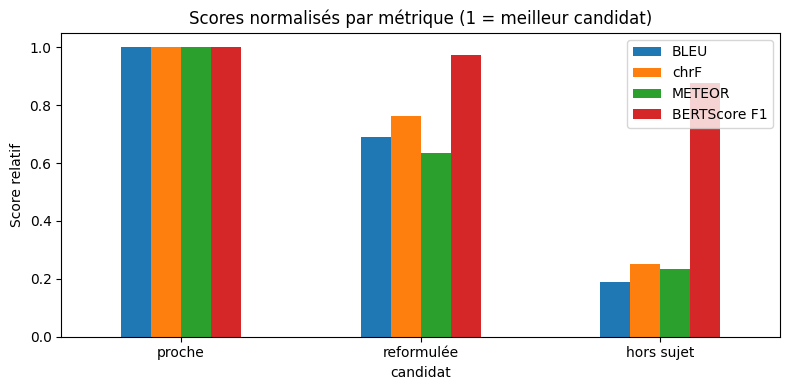

In [19]:
ax = df_gen[["BLEU", "chrF", "METEOR", "BERTScore F1"]].apply(lambda c: c / c.max()).plot(
    kind="bar", figsize=(8, 4), rot=0)
ax.set_title("Scores normalisés par métrique (1 = meilleur candidat)")
ax.set_ylabel("Score relatif")
plt.tight_layout()
plt.show()

## Conclusion
- Aucune métrique unique ne suffit : combiner recouvrement, sémantique et évaluation humaine.
- Pour la Summarization, ajouter une mesure de **factualité**.
- Pour le QA, rapporter **EM et F1** ensemble.
- Pour la génération libre, compléter avec **fluidité, diversité** et un jugement humain ou LLM-juge.